# Cải tiến mô hình

Bản rút gọn của `scripts/tune_models.py` trên **TCB, 6 fold cuối**: đo từng thay đổi trên cùng dữ liệu, cùng fold, cùng chỉ số. Số liệu chính thức ở `docs/train.md`, mục 10.

Chạy lần lượt từ trên xuống (khoảng 2 đến 3 phút).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

SYMBOLS = ["TCB", "CTG", "VNM", "ACB"]
SYMBOL = "TCB"

from preprocess_data import walk_forward_splits
from train_models import CLASSES, RANDOM_STATE, score_fold
from tune_models import MACRO_F1, PARAM_GRIDS, make_estimator, select_features, tune
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import validation_curve

data = pd.read_csv(ROOT / "data/processed/1D" / f"{SYMBOL}.csv")
y = data["label"].to_numpy() + 1
folds = list(walk_forward_splits(len(data), "1D"))[-6:]
results = []


def evaluate(variant, estimator_for, columns):
    X = data[columns].to_numpy()
    for fold, (train, test) in enumerate(folds):
        model = estimator_for(X[train], y[train]).fit(X[train], y[train])
        proba = model.predict_proba(X[test])
        results.append({"variant": variant, "fold": fold, **score_fold(y[test], CLASSES[proba.argmax(axis=1)], proba)})


core, full = select_features("1D", "core"), select_features("1D", "all")
print(f"{len(core)} đặc trưng lõi, {len(full)} đặc trưng đầy đủ, {len(folds)} fold")

12 đặc trưng lõi, 25 đặc trưng đầy đủ, 6 fold


## 1. Đặc trưng: lõi hay đầy đủ

Hạn chế: Random Forest đã quá khớp trên tập huấn luyện. Thử bớt đặc trưng (nhóm lõi theo đề) so với dùng đủ.

In [2]:
rf = lambda X, y: make_estimator("random_forest", balanced=False)
evaluate("RF, đặc trưng lõi", rf, core)
evaluate("RF, đủ đặc trưng", rf, full)

## 2. Siêu tham số

Grid search chọn trên **20% cuối của tập huấn luyện** từng fold, tập test không tham gia chọn. Chỉnh `PARAM_GRIDS["random_forest"]` để đổi không gian tìm kiếm.

In [3]:
print("Lưới:", PARAM_GRIDS["random_forest"])
best_params = []


def tuned_rf(X, y):
    best, params = tune("random_forest", make_estimator("random_forest", balanced=False), X, y, gap=1)
    best_params.append(params)
    return best


evaluate("RF, đủ đặc trưng, đã tinh chỉnh", tuned_rf, full)
pd.DataFrame(best_params).value_counts().rename("số fold chọn")

Lưới: {'max_depth': [3, 5, 8], 'min_samples_leaf': [5, 20]}


max_depth  min_samples_leaf
5          5                   2
8          20                  1
           5                   1
3          5                   1
           20                  1
Name: số fold chọn, dtype: int64

## 3. Đường cong kiểm định

F1 theo độ sâu cây, trên phần huấn luyện và phần validation (20% cuối của train, fold cuối). Hai đường càng tách xa thì càng quá khớp.

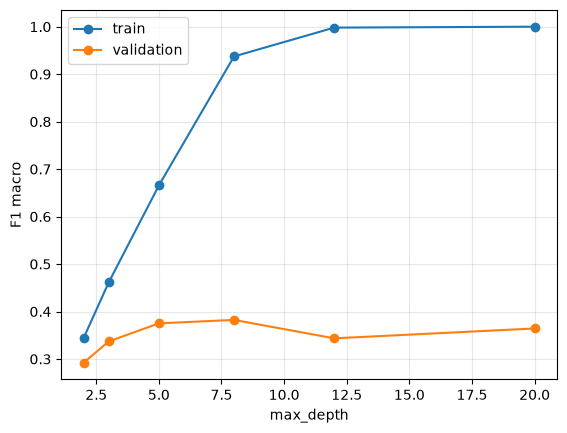

In [4]:
train, _ = folds[-1]
split_at = int(len(train) * 0.8)
depths = [2, 3, 5, 8, 12, 20]
X_full = data[full].to_numpy()
train_scores, val_scores = validation_curve(
    make_estimator("random_forest", balanced=False), X_full[train], y[train], param_name="max_depth", param_range=depths,
    cv=[(np.arange(split_at - 1), np.arange(split_at, len(train)))], scoring=MACRO_F1,
)
plt.plot(depths, train_scores[:, 0], "o-", label="train")
plt.plot(depths, val_scores[:, 0], "o-", label="validation")
plt.xlabel("max_depth")
plt.ylabel("F1 macro")
plt.legend()
plt.show()

**Nhận xét:** F1 trên train tăng từ 0,35 (độ sâu 2) lên 1,00 (độ sâu từ 12), còn trên validation chỉ dao động 0,29 đến 0,38 và cao nhất ở độ sâu 5 đến 8 (khoảng 0,38). Cây càng sâu càng thuộc lòng dữ liệu huấn luyện mà không dự đoán tốt hơn: đó là quá khớp, nên cần giới hạn `max_depth` hoặc tăng `min_samples_leaf`.

## 4. Tổ hợp mô hình

Voting mềm: lấy trung bình xác suất của Logistic, Random Forest, XGBoost. Đây là cách `ensemble3` của mô hình chính kết hợp.

In [5]:
voting = lambda X, y: VotingClassifier(
    [(name, make_estimator(name, balanced=False)) for name in ("logistic", "random_forest", "xgboost")], voting="soft")
evaluate("Voting 3 mô hình", voting, full)
for name in ("logistic", "xgboost"):
    evaluate(f"{name}, đủ đặc trưng", lambda X, y, name=name: make_estimator(name, balanced=False), full)

## 5. So sánh

,accuracy,f1_macro,roc_auc
variant,,,
"RF, đặc trưng lõi",0.349 ± 0.060,0.330 ± 0.052,0.540 ± 0.039
"RF, đủ đặc trưng",0.376 ± 0.037,0.351 ± 0.059,0.542 ± 0.057
"RF, đủ đặc trưng, đã tinh chỉnh",0.381 ± 0.070,0.332 ± 0.061,0.556 ± 0.071
Voting 3 mô hình,0.362 ± 0.077,0.334 ± 0.076,0.541 ± 0.050
"logistic, đủ đặc trưng",0.386 ± 0.052,0.348 ± 0.045,0.554 ± 0.039
"xgboost, đủ đặc trưng",0.352 ± 0.071,0.330 ± 0.071,0.523 ± 0.050


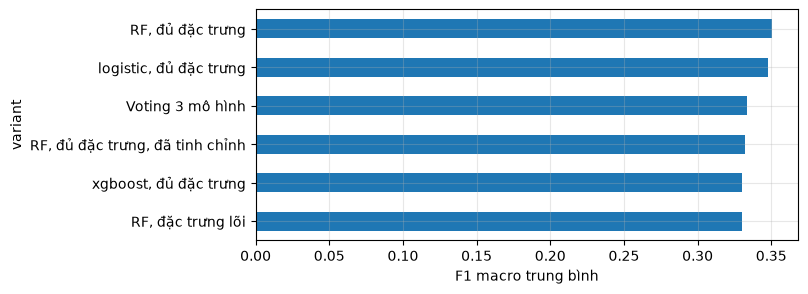

In [6]:
results = pd.DataFrame(results)
mean_std = lambda s: f"{s.mean():.3f} ± {s.std():.3f}"
summary = results.groupby("variant")[["accuracy", "f1_macro", "roc_auc"]].agg(mean_std)
display(summary)
results.groupby("variant").f1_macro.mean().sort_values().plot(kind="barh", figsize=(7, 3), xlabel="F1 macro trung bình")
plt.show()

**Nhận xét** (6 fold cuối, cùng dữ liệu, cùng fold, cùng chỉ số):
- Bớt đặc trưng không giúp: đủ 25 đặc trưng (F1 0,351) hơn nhóm lõi 12 đặc trưng (0,330).
- Tinh chỉnh siêu tham số không tăng F1 trên test (0,332 so với 0,351 mặc định), dù ROC-AUC nhích lên (0,556 so với 0,542). Có thể vì phần validation nhỏ nên việc chọn tham số khớp cả nhiễu.
- Voting 3 mô hình (0,334) không hơn mô hình đơn tốt nhất; Logistic (0,348) ngang Random Forest.
- Mọi chênh lệch đều nhỏ hơn độ lệch chuẩn giữa các fold (0,05 đến 0,08), nên chưa kết luận được hơn kém. Chọn mô hình cuối cần xét thêm độ ổn định, thời gian chạy và khả năng giải thích (xem `docs/train.md`, mục 11).